# Part 2: Shuttle dispatching as an MDP

**How to run:** Run in any tool that can execute a .ipynb file. Figures are saved to a `figures/` folder next to the notebook.

**Execution flow:**
1. Writes the problem down as an MDP (as states, actions, costs, transition probs etc.).
2. Solves it three ways: (a) enumeration over a 500-step horizon, (b) value iteration, (c) policy iteration, and makes the three required plots.
3. Runs tests that check the answers independently: hand calculations, agreement between methods, a simulation that does not uses the equations, brute-force search, and parameter changes with predictions written down before running.

**Notations**

| Symbol | Meaning |
|---|---|
| s | number of customers waiting (the state), 0 … 200 |
| a | action: 0 = wait, 1 = dispatch |
| c(s, a) | cost of taking action a in state s, this step only |
| P(s′ \| s, a) | chance that the next state is s′ |
| γ | discount factor, 0.95 |
| Vₖ(s) | lowest expected discounted cost when exactly k steps are left |
| V\*(s) | lowest expected discounted cost when the process never ends |
| Q(s, a) | expected discounted cost of taking a now and acting optimally afterward |

Values here are **costs**, so lower is better.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

K, C_F, C_H = 15, 100, 2                  # shuttle capacity, dispatch cost, cost per waiting customer per step
ARRIVALS = np.array([1, 2, 3, 4, 5])      # A_t ~ Uniform{1, ..., 5}
ARRIVAL_PROBS = np.full(5, 1 / 5)
S_MAX = 200                               # station capacity
GAMMA = 0.95
T = 500                                   # horizon for part (a)
STATES = np.arange(S_MAX + 1)

os.makedirs("figures", exist_ok=True)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110, "lines.linewidth": 2})

## 1. The model

**Timesteps in order:**
1. Observe s customers waiting.
2. Choose a (0 = wait, 1 = dispatch).
3. If dispatching, min(s, K) customers board and leave.
4. Pay c(s, a) = c_f · a + c_h · (customers left behind).
5. A new customers arrive (1 to 5, each with probability 1/5). The next state is s′ = min(left behind + A, 200).

```
left behind  L(s, a) = max(s − K·a, 0)
cost         c(s, a) = 100·a + 2·L(s, a)
next state   s′      = min(L(s, a) + A, 200)
```

**Assumptions:**
- The waiting cost is charged on the customers left *after* the dispatch (as the assignment says "incurred after dispatch"). New arrivals are first charged in the next step.
- If arrivals would push the count above 200, the extra customers are not counted.
- Dispatching with nobody waiting is allowed (costs 100 and achieves nothing).
- When both actions cost exactly the same, we choose **wait** (a fixed tie rule to keep results reproducible).

The function below stores the whole problem as two tables per action: the cost of every state, and a 201 × 201 matrix of transition probabilities (row = current state, column = next state). The 200 cap is handled automatically: when several arrival outcomes land on 200, their probabilities are added together.

In [2]:
def build_model(K=K, c_f=C_F, c_h=C_H, arrivals=ARRIVALS, probs=ARRIVAL_PROBS, s_max=S_MAX):
    """Returns cost[a, s] = c(s, a) and P[a, s, s'] = P(s' | s, a)."""
    n = s_max + 1
    s = np.arange(n)
    cost = np.zeros((2, n))
    P = np.zeros((2, n, n))
    for a in (0, 1):
        left = np.maximum(s - K * a, 0)
        cost[a] = c_f * a + c_h * left
        for A, p in zip(arrivals, probs):
            nxt = np.minimum(left + A, s_max)
            np.add.at(P[a], (s, nxt), p)       # add, so outcomes that collide at the cap pile up
    return cost, P


cost, P = build_model()

def show_row(s, a):
    nz = np.flatnonzero(P[a, s])
    name = "dispatch" if a else "wait"
    pairs = ", ".join(f"{j}: {P[a, s, j]:.1f}" for j in nz)
    print(f"s = {s:3d}, {name:8s} cost = {cost[a, s]:5.0f}   next state: chance -> {pairs}")

show_row(20, 1)      # the example from the lesson: 110, then 6..10 each 1/5
show_row(20, 0)
show_row(10, 1)      # everyone fits
show_row(198, 0)     # cap: 199 has 1/5, 200 has 4/5
show_row(200, 0)     # stuck at the cap
print("Every row of P adds up to 1:", np.allclose(P.sum(axis=2), 1.0))
print("No negative probabilities:  ", (P >= 0).all())

s =  20, dispatch cost =   110   next state: chance -> 6: 0.2, 7: 0.2, 8: 0.2, 9: 0.2, 10: 0.2
s =  20, wait     cost =    40   next state: chance -> 21: 0.2, 22: 0.2, 23: 0.2, 24: 0.2, 25: 0.2
s =  10, dispatch cost =   100   next state: chance -> 1: 0.2, 2: 0.2, 3: 0.2, 4: 0.2, 5: 0.2
s = 198, wait     cost =   396   next state: chance -> 199: 0.2, 200: 0.8
s = 200, wait     cost =   400   next state: chance -> 200: 1.0
Every row of P adds up to 1: True
No negative probabilities:   True


## 2. Building blocks used by all three methods

`q_values(V)` computes, for every state and both actions,

```
Q(s, a) = c(s, a) + γ · Σ P(s′ | s, a) · V(s′)
```

i.e. *cost now* plus *γ × the average of V over the places you might land*. In matrix form that whole sum is one matrix–vector product, `P[a] @ V`.

`greedy(Q)` picks the cheaper action in every state (wait on ties).

In [3]:
def q_values(V, cost, P, gamma):
    """Q[a, s] for every action and state."""
    return cost + gamma * (P @ V)


def greedy(Q, tol=1e-9):
    """1 (dispatch) only where dispatching is strictly cheaper; ties go to wait."""
    return (Q[1] < Q[0] - tol).astype(int)


def threshold_of(policy):
    """Smallest s at which the policy dispatches (None if it never dispatches)."""
    d = np.flatnonzero(policy == 1)
    return int(d[0]) if len(d) else None


def is_threshold_policy(policy):
    """True if the policy is 'wait below some number, dispatch from it upward'."""
    return bool(np.all(np.diff(policy) >= 0))


def describe(policy):
    th = threshold_of(policy)
    if th is None:
        return "never dispatch"
    return f"dispatch when s >= {th}" + ("" if is_threshold_policy(policy) else " (not a pure threshold rule)")

## 3. Part (a): Enumeration with T = 500

With a fixed horizon there is a known end point: after the last step nothing else happens, so the value of every state is 0. We work backward in time, at each time enumerating every state and every action:

```
V[T](s) = 0                                         for every s
V[t](s) = min over a of  c(s, a) + γ · Σ P(s′ | s, a) · V[t+1](s′)       for t = T−1, …, 0
```

`V[t]` here is Vₖ with k = T − t steps left. The answer to part (a) is `V[0]`, the value with all 500 steps still ahead. We also keep the best action for every (time, state) pair.

Best rule at time 0: dispatch when s >= 13
V0(0) = 576.67 | V0(13) = 676.67 | V0(200) = 3821.59


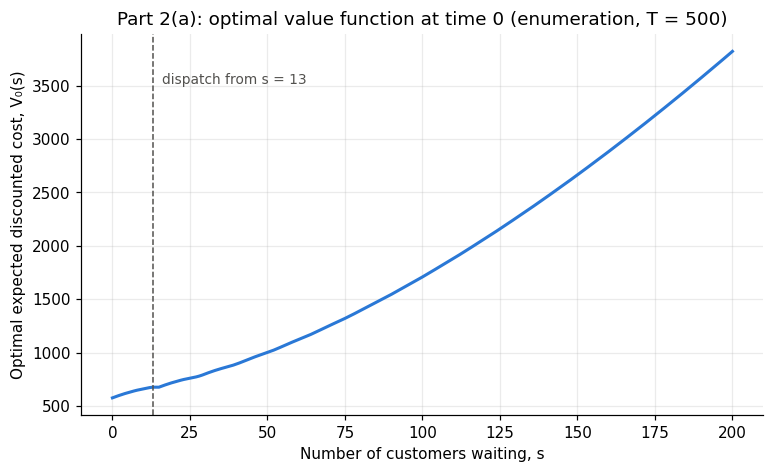

In [4]:
def enumeration(cost, P, gamma, T):
    n = cost.shape[1]
    V = np.zeros((T + 1, n))                  # V[T] = 0: nothing happens after the last step
    policy = np.zeros((T, n), dtype=int)
    for t in range(T - 1, -1, -1):
        Q = q_values(V[t + 1], cost, P, gamma)
        V[t] = Q.min(axis=0)
        policy[t] = greedy(Q)
    return V, policy


V_enum, pol_enum = enumeration(cost, P, GAMMA, T)
V0 = V_enum[0]
print("Best rule at time 0:", describe(pol_enum[0]))
print("V0(0) =", round(V0[0], 2), "| V0(13) =", round(V0[13], 2), "| V0(200) =", round(V0[200], 2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(STATES, V0, color=BLUE)
th = threshold_of(pol_enum[0])
ax.axvline(th, color=GRAY, lw=1, ls="--")
ax.text(th + 3, V0.max() * 0.92, f"dispatch from s = {th}", color=GRAY, fontsize=9)
ax.set_xlabel("Number of customers waiting, s")
ax.set_ylabel("Optimal expected discounted cost, V₀(s)")
ax.set_title("Part 2(a): optimal value function at time 0 (enumeration, T = 500)")
fig.savefig("figures/2a_enumeration_value.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Part (b): Value iteration (T = ∞)

With no end there is no last step to count back from. Value iteration simply repeats the same backward step until the numbers stop changing:

```
start with V(s) = 0 for every s
repeat:  V_new(s) = min over a of  c(s, a) + γ · Σ P(s′ | s, a) · V(s′)
until the largest change max_s |V_new(s) − V(s)| is below a tolerance
```

Why it stops changing: each extra round adds one more step of future, and that step is multiplied by one more factor of 0.95, so the changes shrink by about 5% per round.

**Stopping rule.** If the last change is below `tol`, the remaining error is at most γ · tol / (1 − γ) = 19 · tol. With `tol = 1e-8` the answer is accurate to about 2 × 10⁻⁷.

Value iteration stopped after 429 rounds (last change 9.9e-09)
Best rule: dispatch when s >= 13


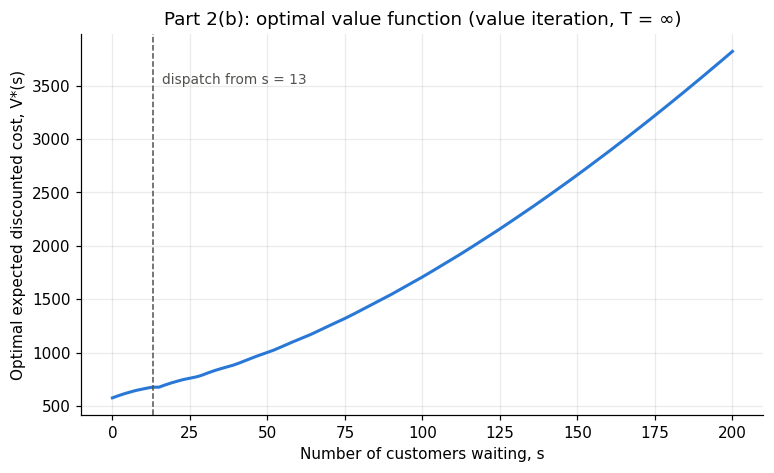

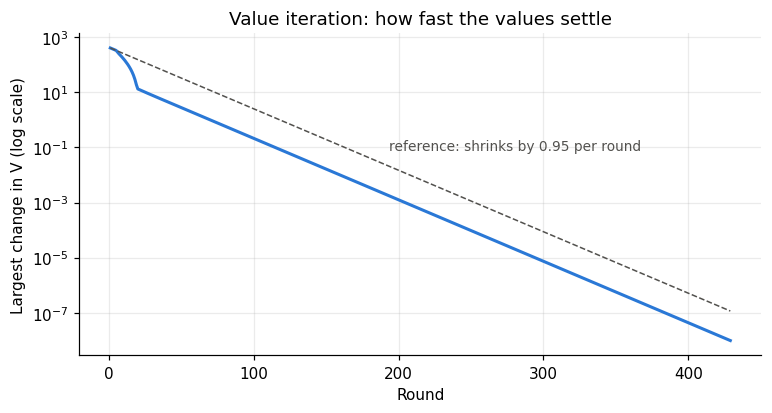

In [5]:
def value_iteration(cost, P, gamma, tol=1e-8, max_rounds=100_000):
    V = np.zeros(cost.shape[1])
    changes = []
    for _ in range(max_rounds):
        V_new = q_values(V, cost, P, gamma).min(axis=0)
        changes.append(np.max(np.abs(V_new - V)))
        V = V_new
        if changes[-1] < tol:
            break
    policy = greedy(q_values(V, cost, P, gamma))
    return V, policy, np.array(changes)


V_star, pol_vi, vi_changes = value_iteration(cost, P, GAMMA)
print(f"Value iteration stopped after {len(vi_changes)} rounds (last change {vi_changes[-1]:.1e})")
print("Best rule:", describe(pol_vi))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(STATES, V_star, color=BLUE)
th = threshold_of(pol_vi)
ax.axvline(th, color=GRAY, lw=1, ls="--")
ax.text(th + 3, V_star.max() * 0.92, f"dispatch from s = {th}", color=GRAY, fontsize=9)
ax.set_xlabel("Number of customers waiting, s")
ax.set_ylabel("Optimal expected discounted cost, V*(s)")
ax.set_title("Part 2(b): optimal value function (value iteration, T = ∞)")
fig.savefig("figures/2b_value_iteration_value.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogy(np.arange(1, len(vi_changes) + 1), vi_changes, color=BLUE)
ax.semilogy(np.arange(1, len(vi_changes) + 1), vi_changes[0] * GAMMA ** np.arange(len(vi_changes)),
            color=GRAY, lw=1, ls="--")
ax.text(len(vi_changes) * 0.45, vi_changes[0] * GAMMA ** (len(vi_changes) * 0.45) * 4,
        "reference: shrinks by 0.95 per round", color=GRAY, fontsize=9)
ax.set_xlabel("Round")
ax.set_ylabel("Largest change in V (log scale)")
ax.set_title("Value iteration: how fast the values settle")
fig.savefig("figures/2b_value_iteration_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Part (c): Policy iteration

Instead of improving the values, improve the **rule**:

1. Start with any rule. We start with "never dispatch".
2. **Evaluate it exactly.** For a fixed rule π there is no "min", so the equation V^π(s) = c(s, π(s)) + γ Σ P(s′|s, π(s)) V^π(s′) is a set of 201 *linear* equations, one per state. In matrix form (I − γ P_π) V^π = c_π, which `np.linalg.solve` solves directly.
3. **Improve it.** Using V^π, compute Q(s, a) for both actions. Wherever the other action is strictly cheaper, switch to it (on a tie, keep the current action, so the loop can't flip back and forth forever).
4. Repeat until no state switches. That rule is optimal.

round | rule being evaluated                | states switched | V(0) under that rule
    1 | never dispatch                      |             196 |    2203.91
    2 | dispatch when s >= 3 (not a pure threshold rule) |              28 |    1330.47
    3 | dispatch when s >= 26 (not a pure threshold rule) |              22 |     890.79
    4 | dispatch when s >= 7                |               7 |     748.61
    5 | dispatch when s >= 14               |               1 |     581.58
    6 | dispatch when s >= 13               |               0 |     576.67

Optimal rule: dispatch when s >= 13


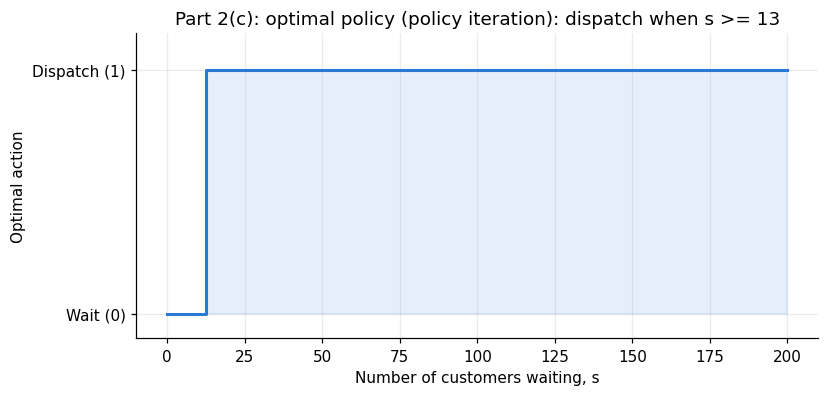

In [6]:
def evaluate_policy(policy, cost, P, gamma):
    """Exact V^pi by solving (I - gamma * P_pi) V = c_pi."""
    n = len(policy)
    rows = np.arange(n)
    P_pi = P[policy, rows]            # row s comes from the matrix of the action the rule picks in s
    c_pi = cost[policy, rows]
    return np.linalg.solve(np.eye(n) - gamma * P_pi, c_pi)


def policy_iteration(cost, P, gamma, start_policy=None, max_rounds=1000):
    n = cost.shape[1]
    policy = np.zeros(n, dtype=int) if start_policy is None else np.array(start_policy, dtype=int)
    log = []
    rows = np.arange(n)
    for r in range(1, max_rounds + 1):
        V = evaluate_policy(policy, cost, P, gamma)
        Q = q_values(V, cost, P, gamma)
        switch = Q[1 - policy, rows] < Q[policy, rows] - 1e-9
        log.append((r, describe(policy), int(switch.sum()), V[0]))
        if not switch.any():
            return policy, V, log
        policy = np.where(switch, 1 - policy, policy)
    raise RuntimeError("policy iteration did not converge")


pol_pi, V_pi, pi_log = policy_iteration(cost, P, GAMMA)
print("round | rule being evaluated                | states switched | V(0) under that rule")
for r, d, n_sw, v0 in pi_log:
    print(f"{r:5d} | {d:35s} | {n_sw:15d} | {v0:10.2f}")
print("\nOptimal rule:", describe(pol_pi))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.step(STATES, pol_pi, where="mid", color=BLUE)
ax.fill_between(STATES, pol_pi, step="mid", color=BLUE, alpha=0.12)
ax.set_yticks([0, 1], ["Wait (0)", "Dispatch (1)"])
ax.set_ylim(-0.1, 1.15)
ax.set_xlabel("Number of customers waiting, s")
ax.set_ylabel("Optimal action")
ax.set_title(f"Part 2(c): optimal policy (policy iteration): {describe(pol_pi)}")
fig.savefig("figures/2c_policy_iteration_policy.png", dpi=150, bbox_inches="tight")
plt.show()

# Tests: how do we know these answers are right?

Each test says **what it checks, what we predict before running it, and why a match is convincing**. Several tests deliberately avoid the Bellman equation altogether (simulation, brute force), so they can catch mistakes that the three methods would share.

## Test 1: Hand calculations and the first 10 rounds

**Prediction (worked out by hand before running anything):**
- With 1 step left, dispatching costs 70 more than waiting whenever s > 15 (it costs 100 but saves 15 × 2 = 30), and 100 versus at most 30 when s ≤ 15. So V₁(s) = 2s for every s, and the best action is always wait.
- V₂(20) = 40 + 0.95 × 46 = 83.7 and V₂(30) = 60 + 0.95 × 66 = 122.7.
- **When can dispatching first pay off?** Dispatching costs 100 now and removes at most 15 people, which saves at most 2 × 15 = 30 per remaining step. With k steps left, the most it can save is 30 × (1 + γ + … + γᵏ⁻¹): 30, 58.5, 85.6, 111.3 for k = 1, 2, 3, 4. So **no dispatch can be optimal with 3 or fewer steps left**, and dispatching can first appear at k = 4.

In [7]:
V1 = V_enum[T - 1]; V2 = V_enum[T - 2]
print("V1(s) == 2s for every s:", np.allclose(V1, 2 * STATES))
print(f"V2(20) = {V2[20]:.4f}   (hand: 83.7)")
print(f"V2(30) = {V2[30]:.4f}   (hand: 122.7)")

savings = [30 * sum(GAMMA ** i for i in range(k)) for k in range(1, 6)]
print("\nMost a dispatch can save with k steps left:", [round(x, 1) for x in savings])

print("\nSteps left k | best rule with k steps left       | V_k(20)  | V_k(30)")
for k in range(1, 11):
    print(f"{k:12d} | {describe(pol_enum[T - k]):33s} | {V_enum[T - k][20]:8.1f} | {V_enum[T - k][30]:8.1f}")
first_k = next(k for k in range(1, T + 1) if threshold_of(pol_enum[T - k]) is not None)
print(f"\nFirst k at which any dispatch is optimal: {first_k}   (prediction: 4)")

V1(s) == 2s for every s: True
V2(20) = 83.7000   (hand: 83.7)
V2(30) = 122.7000   (hand: 122.7)

Most a dispatch can save with k steps left: [30.0, 58.5, 85.6, 111.3, 135.7]

Steps left k | best rule with k steps left       | V_k(20)  | V_k(30)
           1 | never dispatch                    |     40.0 |     60.0
           2 | never dispatch                    |     83.7 |    122.7
           3 | never dispatch                    |    130.6 |    187.7
           4 | dispatch when s >= 14 (not a pure threshold rule) |    169.1 |    243.3
           5 | dispatch when s >= 12 (not a pure threshold rule) |    196.8 |    276.5
           6 | dispatch when s >= 13             |    227.0 |    299.7
           7 | dispatch when s >= 13             |    253.8 |    326.0
           8 | dispatch when s >= 13             |    275.3 |    352.4
           9 | dispatch when s >= 13             |    296.1 |    375.0
          10 | dispatch when s >= 13             |    318.2 |    394.8

First k at w

## Test 2: The three methods agree

**Prediction:**
- Enumeration (T = 500) and value iteration (T = ∞) differ only by costs that occur after step 500, which are multiplied by γ⁵⁰⁰ ≈ 7 × 10⁻¹². So the two value functions should match to about γ⁵⁰⁰ × max V\* plus value iteration's own tolerance.
- All three methods solve the same problem, so all three must give the same rule.
- The values from policy iteration (an exact linear solve) must match value iteration's.

max |V0_enumeration - V*_value_iteration| = 1.84e-07   (predicted at most 2.2e-07)
max |V_policy_iteration - V*_value_iteration| = 1.89e-07
Same rule, enumeration vs value iteration: True
Same rule, policy iteration vs value iteration: True


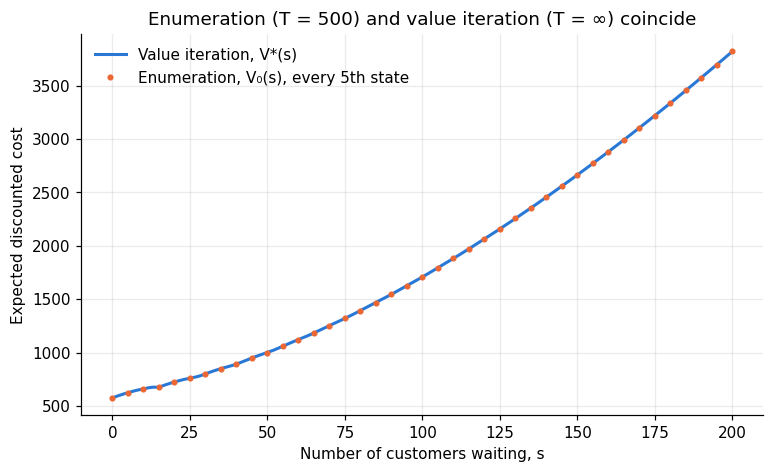

In [8]:
bound = GAMMA ** T * V_star.max() + 19 * 1e-8
print(f"max |V0_enumeration - V*_value_iteration| = {np.max(np.abs(V0 - V_star)):.2e}   (predicted at most {bound:.1e})")
print(f"max |V_policy_iteration - V*_value_iteration| = {np.max(np.abs(V_pi - V_star)):.2e}")
print("Same rule, enumeration vs value iteration:", np.array_equal(pol_enum[0], pol_vi))
print("Same rule, policy iteration vs value iteration:", np.array_equal(pol_pi, pol_vi))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(STATES, V_star, color=BLUE, label="Value iteration, V*(s)")
ax.plot(STATES, V0, color=ORANGE, lw=0, marker="o", ms=3, markevery=5, label="Enumeration, V₀(s), every 5th state")
ax.set_xlabel("Number of customers waiting, s")
ax.set_ylabel("Expected discounted cost")
ax.set_title("Enumeration (T = 500) and value iteration (T = ∞) coincide")
ax.legend(frameon=False)
fig.savefig("figures/test_2_methods_agree.png", dpi=150, bbox_inches="tight")
plt.show()

## Test 3: Properties the answer must have

**Prediction:**
- **Bellman check.** Plugging V\* back into its own equation must return V\* (residual ≈ 0).
- **More waiting can't be cheaper.** V\*(s) should never decrease as s grows.
- **Threshold shape.** If dispatching is right with s waiting, it should also be right with more waiting: wait below some number, dispatch from it upward.
- **A flat stretch from 13 to 15.** Dispatching at 13, 14 or 15 puts *everyone* on the shuttle: same cost (100), same next state (1–5 waiting). So V\*(13) = V\*(14) = V\*(15) exactly.

In [9]:
residual = np.max(np.abs(V_star - q_values(V_star, cost, P, GAMMA).min(axis=0)))
print(f"Bellman residual max_s |V*(s) - min_a Q(s,a)| = {residual:.1e}")
print("V* never decreases as s grows:", bool(np.all(np.diff(V_star) >= -1e-9)))
print("Optimal policy is a threshold rule:", is_threshold_policy(pol_vi))
print("V*(12..16):", np.round(V_star[12:17], 4))
print("V*(13) == V*(14) == V*(15):", np.isclose(V_star[13], V_star[14]) and np.isclose(V_star[14], V_star[15]))

Bellman residual max_s |V*(s) - min_a Q(s,a)| = 9.4e-09
V* never decreases as s grows: True
Optimal policy is a threshold rule: True
V*(12..16): [672.8922 676.6702 676.6702 676.6702 687.4441]
V*(13) == V*(14) == V*(15): True


## Test 4: Simulation that never uses the equations

**What it does:** plays the optimal rule many times with random arrivals, writing the shuttle rules directly (not through the `P` matrix), and averages the discounted cost over 20,000 runs of 400 steps (γ⁴⁰⁰ ≈ 10⁻⁹, so stopping at 400 changes nothing).

**Prediction:** the simulated average from each starting state should fall within its 95% confidence interval of V\*(s). Because this test shares no code with the solvers, a match also confirms that `build_model` describes the real problem.

In [10]:
def simulate(policy, s0, n_runs=20_000, horizon=400, seed=0):
    rng = np.random.default_rng(seed)
    s = np.full(n_runs, s0)
    total = np.zeros(n_runs)
    disc = 1.0
    for _ in range(horizon):
        a = policy[s]
        left = np.where(a == 1, np.maximum(s - K, 0), s)
        total += disc * (C_F * a + C_H * left)
        disc *= GAMMA
        s = np.minimum(left + rng.integers(1, 6, size=n_runs), S_MAX)
    return total


print("start s | V*(s)   | simulated mean ± 95% CI | inside?")
for s0 in [0, 13, 50, 100, 200]:
    g = simulate(pol_vi, s0, seed=s0)
    half = 1.96 * g.std(ddof=1) / np.sqrt(len(g))
    print(f"{s0:7d} | {V_star[s0]:7.1f} | {g.mean():7.1f} ± {half:4.1f}         | {abs(g.mean() - V_star[s0]) <= half}")

start s | V*(s)   | simulated mean ± 95% CI | inside?
      0 |   576.7 |   576.7 ±  0.4         | True
     13 |   676.7 |   676.6 ±  0.4         | True
     50 |  1001.5 |  1001.5 ±  0.4         | True
    100 |  1709.0 |  1709.0 ±  0.6         | True
    200 |  3821.6 |  3821.8 ±  1.0         | True


## Test 5: Brute force over every threshold rule

**What it does:** evaluates *every* rule of the form "dispatch when s ≥ θ" for θ = 0, 1, …, 201 (θ = 201 means never dispatch), exactly, with the policy-evaluation solver, and plots the cost of each when starting from an empty station.

**Prediction:** the cheapest θ is the threshold found by the three methods, and its values equal V\*. Starting at θ = 0 (always dispatch) the cost should be high, fall to a minimum, then rise again as waiting costs pile up. This is the same trade-off as in the shuttle game from Lesson 1.

Cheapest threshold (starting empty): 13 | from value iteration: 13
Same threshold is cheapest from every starting state: True
max |V_theta_best - V*| = 1.9e-07


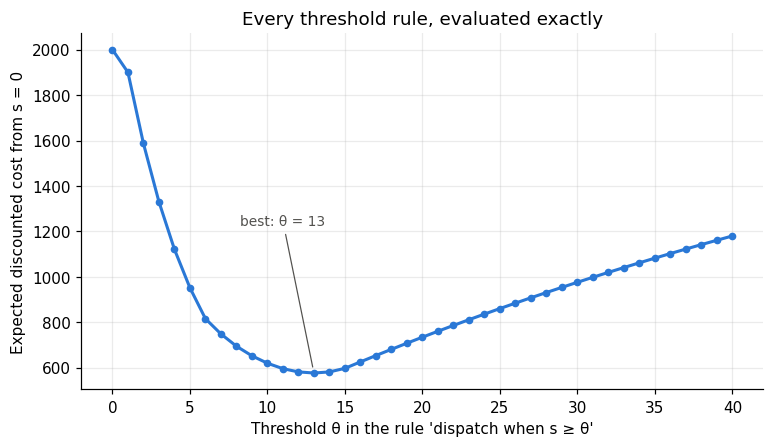

In [11]:
thetas = np.arange(0, S_MAX + 2)
V_theta = np.array([evaluate_policy((STATES >= th).astype(int), cost, P, GAMMA) for th in thetas])
best_theta = thetas[np.argmin(V_theta[:, 0])]
print("Cheapest threshold (starting empty):", best_theta, "| from value iteration:", threshold_of(pol_vi))
print("Same threshold is cheapest from every starting state:",
      bool(np.all(thetas[np.argmin(V_theta, axis=0)] == best_theta)))
print(f"max |V_theta_best - V*| = {np.max(np.abs(V_theta[best_theta] - V_star)):.1e}")

fig, ax = plt.subplots(figsize=(8, 4.2))
show = thetas <= 40
ax.plot(thetas[show], V_theta[show, 0], color=BLUE, marker="o", ms=4)
ax.annotate(f"best: θ = {best_theta}", (best_theta, V_theta[best_theta, 0]),
            xytext=(best_theta - 2, V_theta[best_theta, 0] + 650), color=GRAY, fontsize=9, ha="center",
            arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8, shrinkB=4))
ax.set_xlabel("Threshold θ in the rule 'dispatch when s ≥ θ'")
ax.set_ylabel("Expected discounted cost from s = 0")
ax.set_title("Every threshold rule, evaluated exactly")
fig.savefig("figures/test_5_threshold_brute_force.png", dpi=150, bbox_inches="tight")
plt.show()

## Test 6: True enumeration with deterministic arrivals

The assignment suggests reducing randomness. With exactly 3 arrivals every step, the problem has no luck at all, so for a short horizon we can **try every possible sequence of actions** (2¹⁸ = 262,144 sequences for 18 steps) and take the cheapest.

**Prediction:** the cheapest sequence costs exactly what backward induction (our part (a) code) computes for the same deterministic problem.

In [12]:
T_small = 18
cost_d, P_d = build_model(arrivals=np.array([3]), probs=np.array([1.0]))
V_d, _ = enumeration(cost_d, P_d, GAMMA, T_small)

seqs = ((np.arange(2 ** T_small)[:, None] >> np.arange(T_small)) & 1)      # every action sequence, one per row
print("start s | backward induction | best of 262,144 sequences | match")
for s0 in [0, 7, 13, 20, 45]:
    s = np.full(len(seqs), s0)
    total = np.zeros(len(seqs))
    for t in range(T_small):
        a = seqs[:, t]
        left = np.where(a == 1, np.maximum(s - K, 0), s)
        total += GAMMA ** t * (C_F * a + C_H * left)
        s = np.minimum(left + 3, S_MAX)
    print(f"{s0:7d} | {V_d[0][s0]:18.4f} | {total.min():25.4f} | {np.isclose(V_d[0][s0], total.min())}")

start s | backward induction | best of 262,144 sequences | match
      0 |           306.7667 |                  306.7667 | True
      7 |           369.9584 |                  369.9584 | True
     13 |           406.7667 |                  406.7667 | True
     20 |           453.2490 |                  453.2490 | True
     45 |           680.5167 |                  680.5167 | True


## Test 7: Change the problem and check the answer moves the right way

Predictions written **before** running:

| Change | Prediction | Reason |
|---|---|---|
| γ = 0 | never dispatch, V(s) = 2s | only this step counts, and dispatching always costs more this step |
| γ ≤ 0.7 | never dispatch | the most a dispatch can save is 2·15·(1 + γ + γ² + …) = 30/(1 − γ), which is ≤ 100 exactly when γ ≤ 0.7 |
| γ = 0.71 | dispatching appears | 30/(1 − 0.71) ≈ 103 > 100 |
| c_h = 0 | never dispatch, V = 0 | waiting is free |
| c_f = 0 | dispatch whenever s ≥ 1 | dispatching is free and removes people |
| c_f = 10⁶ | never dispatch | a dispatch can never pay for itself |
| c_f ↑ (50 → 400) | threshold rises | each dispatch is pricier, so wait for a fuller shuttle |
| c_h ↑ (1 → 8) | threshold falls | waiting is pricier, so dispatch sooner |
| γ ↑ (0.75 → 0.99) | threshold falls or stays | future savings count more |

In [13]:
def solve(**kw):
    gamma = kw.pop("gamma", GAMMA)
    c, Pm = build_model(**kw)
    V, pol, _ = value_iteration(c, Pm, gamma)
    return V, pol

rows = []
V, pol = solve(gamma=0.0);   rows.append(("gamma = 0", describe(pol), f"V == 2s: {np.allclose(V, 2 * STATES)}"))
for g in [0.5, 0.7, 0.71]:
    V, pol = solve(gamma=g); rows.append((f"gamma = {g}", describe(pol), ""))
V, pol = solve(c_h=0);       rows.append(("c_h = 0", describe(pol), f"V == 0: {np.allclose(V, 0)}"))
V, pol = solve(c_f=0);       rows.append(("c_f = 0", describe(pol), ""))
V, pol = solve(c_f=1e6);     rows.append(("c_f = 1e6", describe(pol), ""))
for name, key, vals in [("c_f", "c_f", [50, 100, 200, 400]), ("c_h", "c_h", [1, 2, 4, 8]),
                        ("gamma", "gamma", [0.75, 0.8, 0.9, 0.95, 0.99])]:
    ths = [threshold_of(solve(**{key: v})[1]) for v in vals]
    rows.append((f"{name} = {vals}", f"thresholds {ths}", ""))
for r in rows:
    print(f"{r[0]:32s} -> {r[1]:45s} {r[2]}")

gamma = 0                        -> never dispatch                                V == 2s: True
gamma = 0.5                      -> never dispatch                                
gamma = 0.7                      -> never dispatch                                
gamma = 0.71                     -> dispatch when s >= 15 (not a pure threshold rule) 
c_h = 0                          -> never dispatch                                V == 0: True
c_f = 0                          -> dispatch when s >= 1                          
c_f = 1e6                        -> never dispatch                                
c_f = [50, 100, 200, 400]        -> thresholds [11, 13, 14, 15]                   
c_h = [1, 2, 4, 8]               -> thresholds [14, 13, 11, 8]                    
gamma = [0.75, 0.8, 0.9, 0.95, 0.99] -> thresholds [15, 14, 13, 13, 13]               


## Test 8: Follow the optimal rule for 10 steps

The assignment suggests isolating the first 10 steps to see how states, costs, values and the policy interact. Each row shows the state, the two Q-values (the rule picks the smaller), the cost paid, the arrivals, and the running discounted total.

In [14]:
rng = np.random.default_rng(7)
Q_star = q_values(V_star, cost, P, GAMMA)
s, total = 0, 0.0
print(" t |  s | Q(s,wait) | Q(s,disp) | action   | cost | arrivals | next s | discounted total")
for t in range(10):
    a = pol_vi[s]
    left = max(s - K * a, 0)
    c = C_F * a + C_H * left
    total += GAMMA ** t * c
    A = int(rng.integers(1, 6))
    s_next = min(left + A, S_MAX)
    print(f"{t:2d} | {s:2d} | {Q_star[0, s]:9.1f} | {Q_star[1, s]:9.1f} | {'dispatch' if a else 'wait':8s} | "
          f"{c:4d} | {A:8d} | {s_next:6d} | {total:8.1f}")
    s = s_next

 t |  s | Q(s,wait) | Q(s,disp) | action   | cost | arrivals | next s | discounted total
 0 |  0 |     576.7 |     676.7 | wait     |    0 |        5 |      5 |      0.0
 1 |  5 |     625.4 |     676.7 | wait     |   10 |        4 |      9 |      9.5
 2 |  9 |     655.0 |     676.7 | wait     |   18 |        4 |     13 |     25.7
 3 | 13 |     680.8 |     676.7 | dispatch |  100 |        5 |      5 |    111.5
 4 |  5 |     625.4 |     676.7 | wait     |   10 |        3 |      8 |    119.6
 5 |  8 |     648.9 |     676.7 | wait     |   16 |        4 |     12 |    132.0
 6 | 12 |     672.9 |     676.7 | wait     |   24 |        5 |     17 |    149.7
 7 | 17 |     722.8 |     697.8 | dispatch |  104 |        2 |      4 |    222.3
 8 |  4 |     616.8 |     676.7 | wait     |    8 |        1 |      5 |    227.6
 9 |  5 |     625.4 |     676.7 | wait     |   10 |        2 |      7 |    233.9


# Edge cases

## Edge case: the end of a finite horizon

With only a few steps left, a dispatch has no time to pay for itself (Test 1), so near the end of part (a) the best rule changes. This plot shows the threshold at every time t in the 500-step problem. Far from the end it equals the infinite-horizon answer; in the last few steps it moves, and with 3 or fewer steps left dispatching disappears entirely. (With 4–5 steps left, waiting is also optimal at 196–200 because of the cap, see the next edge case.)

Threshold with 1..10 steps left: [None, None, None, 14, 12, 13, 13, 13, 13, 13]
Threshold is constant for all t with more than 10 steps left: [13.]


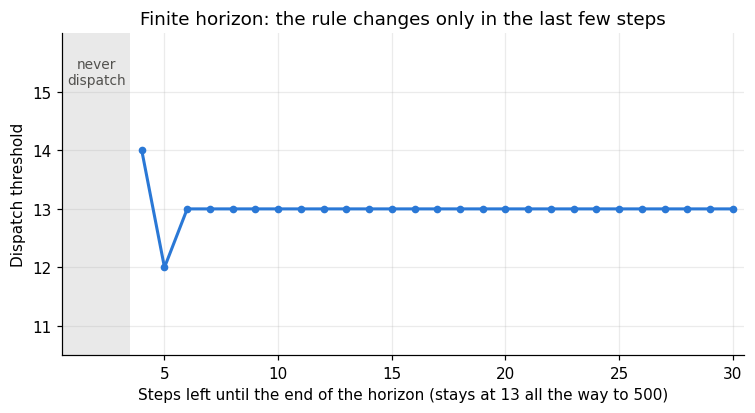

In [15]:
th_t = np.array([threshold_of(pol_enum[t]) if threshold_of(pol_enum[t]) is not None else np.nan for t in range(T)])
steps_left = T - np.arange(T)
print("Threshold with 1..10 steps left:", [None if np.isnan(x) else int(x) for x in th_t[::-1][:10]])
print("Threshold is constant for all t with more than 10 steps left:", np.unique(th_t[steps_left > 10]))

fig, ax = plt.subplots(figsize=(8, 3.8))
k_show = np.arange(1, 31)
th_show = th_t[::-1][:30]
ax.axvspan(0.5, 3.5, color=GRAY, alpha=0.12, lw=0)
ax.text(2, 15.6, "never\ndispatch", ha="center", va="top", color=GRAY, fontsize=9)
ax.plot(k_show, th_show, color=BLUE, marker="o", ms=4)
ax.set_xlim(0.5, 30.5)
ax.set_ylim(10.5, 16)
ax.set_yticks(range(11, 16))
ax.set_xlabel("Steps left until the end of the horizon (stays at 13 all the way to 500)")
ax.set_ylabel("Dispatch threshold")
ax.set_title("Finite horizon: the rule changes only in the last few steps")
fig.savefig("figures/edge_finite_horizon_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

## Edge case: the 200-person cap

Turning away arrivals at 200 makes waiting look artificially cheap there: a full station *can't get any fuller*, so the usual reason to dispatch (stop the crowd growing) disappears. With our settings this doesn't change the optimal rule (Test 3: it is a clean threshold rule). But in less far-sighted settings it does: with γ = 0.71, the optimal rule dispatches in the middle range yet **waits at 200**. That's an artifact of the cap assumption, not of real shuttles, and it's why the cap assumption belongs in the report.

In [16]:
c71, P71 = build_model()
V71, pol71, _ = value_iteration(c71, P71, 0.71)
waits_high = STATES[(pol71 == 0) & (STATES > threshold_of(pol71))]
print("gamma = 0.71:", describe(pol71))
print("States above the threshold where waiting is still optimal:", waits_high)
print("Base case (gamma = 0.95) waits anywhere above its threshold:",
      bool(np.any((pol_vi == 0) & (STATES > threshold_of(pol_vi)))))

gamma = 0.71: dispatch when s >= 15 (not a pure threshold rule)
States above the threshold where waiting is still optimal: [187 188 189 190 191 192 193 194 195 196 197 198 199 200]
Base case (gamma = 0.95) waits anywhere above its threshold: False


## Other edge cases handled in the code

| Edge case | How it's handled |
|---|---|
| Dispatch with fewer than K waiting | `max(s − K·a, 0)`: everyone boards, nobody is left, no negative people |
| Dispatch with more than K waiting | the extra customers stay and are charged c_h each |
| Dispatch with 0 waiting | allowed; costs 100 for nothing, so it is never optimal (V\*(0) uses wait) |
| s = 0 after the start | impossible, since at least 1 customer arrives each step; s = 0 only matters as a starting state |
| Arrivals above 200 | turned away; colliding probabilities are added, so every row of P still sums to 1 (Section 1) |
| Ties between actions | always wait in value iteration; keep the current action in policy iteration, which prevents endless switching |
| Stopping value iteration | stop when the largest change is below 10⁻⁸, which bounds the error by 19 × 10⁻⁸ |
| Discounting in part (a) | γ = 0.95 is also applied in the finite-horizon problem, as the assignment specifies |

# Notes for the report

**Results.** All three methods give the same rule, **dispatch when 13 or more customers are waiting**, and the same value function (differences around 10⁻⁷ or smaller).

**Ideas for "3 more months":**
- Replace the uniform arrival assumption with real arrival data (time-of-day patterns), which requires adding the time of day to the state.
- Study the cap: compare "turn away" with "customers stay but aren't counted", and with a larger cap, to measure how much the assumption affects the answer.
- Model multiple shuttles, travel times (a dispatched shuttle is unavailable for several steps), or partial dispatches.
- Compare these exact methods with learning methods (Q-learning) that don't know P, and measure how many simulated steps they need to find θ = 13.
- Prove the threshold structure formally and check how it breaks as parameters change (as with the cap at γ = 0.71).